# ACS experiment figures

Regenerates the experiment figures of the paper in `../figures_final/` (PDF and PNG).

- **Figure 8** (single-feature Pareto frontiers): `intro_diff_scale_*`; panel (f) is also **Figure 5**
- **Figure 9** (risk and relative improvement as functions of $\beta$): `fig1_analog_*`, panels (a)–(e). Panel (f) is also **Figure 1** and is drawn by `figure1_nd_race_age.ipynb`.
- **Figure 10** (four-feature Pareto frontiers): `intro_diff_scale_*_all_features_*`, `intro_diff_scale_ND_*_all4`

In [1]:
import os
import numpy as np
import importlib
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

warnings.filterwarnings('ignore')

import folktables_utils
import train_methods
importlib.reload(folktables_utils)
importlib.reload(train_methods)

from folktables_utils import load_acs_income
from train_methods import (
    solve_weighted_groups_closed_form,
    train_group_oracles,
    compute_baseline_losses,
)

import matplotlib.pyplot as plt
plt.rcParams['font.family']      = 'serif'
plt.rcParams['font.size']        = 9
plt.rcParams['axes.labelsize']   = 10
plt.rcParams['xtick.labelsize']  = 9
plt.rcParams['ytick.labelsize']  = 9
plt.rcParams['legend.fontsize']  = 8
plt.rcParams['lines.linewidth']  = 1.5

YEAR       = 2018
NUM_LAMBDAS = 10001
lambdas    = np.linspace(0, 1, NUM_LAMBDAS)
FEATS_4    = ['AGEP', 'SCHL', 'MARC', 'RELPC']

OUT_DIR = '../figures_final'
os.makedirs(OUT_DIR, exist_ok=True)
print(f'Output: {OUT_DIR}')

Output: ../figures_final


In [2]:
GROUP_NAMES = {'sex': ('Male', 'Female'), 'race_binary': ('White', 'Non-White')}


def run_config(state, group_by, features):
    """Load data, compute Pareto frontier and all method indices."""
    g0_name, g1_name = GROUP_NAMES[group_by]
    X, y, g, num_groups, _ = load_acs_income(
        states=(state,), year=YEAR, group_by=group_by,
        features=features, employed_only=True
    )
    X_sc = StandardScaler().fit_transform(X)
    base = compute_baseline_losses(y, g, num_groups)
    orac = train_group_oracles(X_sc, y, g, num_groups=num_groups,
                               closed_form=True, verbose=False)
    gap  = base - orac

    coefs_betas = []
    risks = []
    for lam in lambdas:
        coef, _, rmse = solve_weighted_groups_closed_form(X_sc, y, g, num_groups, lam)
        risks.append(rmse)
        coefs_betas.append(coef[0])          # slope of first feature
    cp    = np.array(risks)
    betas = np.array(coefs_betas)            # meaningful only for single-feature

    erm_lam  = (g == 1).sum() / len(g)
    erm_idx  = np.argmin(np.abs(lambdas - erm_lam))
    dro_idx  = np.argmin(cp.max(axis=1))
    regrets  = cp - orac[np.newaxis, :]
    mmr_idx  = np.argmin(regrets.max(axis=1))
    ri_all   = (base[np.newaxis, :] - cp) / gap[np.newaxis, :]
    mri_idx  = np.argmax(ri_all.min(axis=1))
    surplus  = base[np.newaxis, :] - cp
    valid    = np.all(surplus > 0, axis=1)
    nash_prod = np.prod(surplus, axis=1)
    nash_prod[~valid] = -np.inf
    nash_idx = np.argmax(nash_prod)
    mmv_min  = surplus.min(axis=1).copy()
    mmv_min[~valid] = -np.inf
    mmv_idx  = np.argmax(mmv_min)

    # group-specific oracle betas
    beta0_oracle = LinearRegression().fit(X_sc[g==0], y[g==0]).coef_[0]
    beta1_oracle = LinearRegression().fit(X_sc[g==1], y[g==1]).coef_[0]

    methods = {
        'ERM':  cp[erm_idx],  'GDRO': cp[dro_idx],
        'MMR':  cp[mmr_idx],  'MMRI': cp[mri_idx],
        'Nash': cp[nash_idx], 'MMV':  cp[mmv_idx],
    }
    ri_mmr = (base - cp[mmr_idx]) / gap
    ri_mri = (base - cp[mri_idx]) / gap

    print(f'{state}/{group_by}/{features}  ratio={gap[0]/gap[1]:.4f}')
    print(f'  MMR:  {g0_name}={ri_mmr[0]*100:.1f}%  {g1_name}={ri_mmr[1]*100:.1f}%')
    print(f'  MMRI: {g0_name}={ri_mri[0]*100:.1f}%  {g1_name}={ri_mri[1]*100:.1f}%')

    return dict(
        X_sc=X_sc, y=y, g=g, num_groups=num_groups,
        base=base, orac=orac, gap=gap, cp=cp, betas=betas,
        beta0_oracle=beta0_oracle, beta1_oracle=beta1_oracle,
        erm_idx=erm_idx, dro_idx=dro_idx, mmr_idx=mmr_idx,
        mri_idx=mri_idx, nash_idx=nash_idx, mmv_idx=mmv_idx,
        methods=methods, ri_mmr=ri_mmr, ri_mri=ri_mri,
        g0=g0_name, g1=g1_name,
    )


def plot_pareto_front(d, save_path, legend_loc='lower right'):
    """Pareto frontier plot with method solutions. No title."""
    base, orac, cp, methods = d['base'], d['orac'], d['cp'], d['methods']
    g0, g1 = d['g0'], d['g1']

    fig, ax = plt.subplots(figsize=(5.0, 4.5))
    si = np.argsort(cp[:, 0])
    ax.plot(cp[si, 0], cp[si, 1], color='grey', linewidth=2.5, label='Pareto Frontier')
    ax.plot([base[0], orac[0]], [base[1], orac[1]],
            color='purple', linewidth=2.0, linestyle='-.', label='Equal RI')
    ax.scatter(base[0], base[1], color='black', s=120,
               marker='P', zorder=5, label='Baseline')
    ax.scatter(orac[0], orac[1], color='red', s=140,
               marker='*', zorder=5, label='Ideal Point')
    ax.scatter(*methods['GDRO'], color='green',   s=120, marker='X',
               edgecolors='black', linewidths=1.5, zorder=10, label='Group DRO')
    ax.scatter(*methods['MMV'],  color='blue',    s=120, marker='P',
               edgecolors='black', linewidths=1.5, zorder=10, label='MMV')
    ax.scatter(*methods['MMRI'], color='orange',  s=120, marker='D',
               edgecolors='black', linewidths=1.5, zorder=10, label='MMRI')
    ax.scatter(*methods['MMR'],  color='yellow',  s=120, marker='s',
               edgecolors='black', linewidths=1.5, zorder=10, label='MMR')
    ax.scatter(*methods['ERM'],  color='grey',    s=120, marker='h',
               edgecolors='black', linewidths=1.5, zorder=10, label='ERM')
    ax.scatter(*methods['Nash'], color='crimson', s=120, marker='o',
               edgecolors='black', linewidths=1.5, zorder=10, label='Nash')
    ax.set_xlabel(f'Group 0 RMSE ({g0})', fontsize=11)
    ax.set_ylabel(f'Group 1 RMSE ({g1})', fontsize=11)
    ax.legend(loc=legend_loc, fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    for ext in ('pdf', 'png'):
        plt.savefig(f'{save_path}.{ext}', dpi=300, bbox_inches='tight')
    print(f'  Saved: {save_path}.pdf')
    plt.show()


def plot_beta_sweep(d, save_path):
    """Risk & RI vs beta plot. No title. For single-feature models only."""
    base, orac, gap   = d['base'], d['orac'], d['gap']
    cp, betas         = d['cp'], d['betas']
    mmr_idx, mri_idx  = d['mmr_idx'], d['mri_idx']
    b0_oracle, b1_oracle = d['beta0_oracle'], d['beta1_oracle']
    g0, g1            = d['g0'], d['g1']

    si    = np.argsort(betas)
    bs    = betas[si]
    r0s   = cp[si, 0];  r1s   = cp[si, 1]
    rho0s = (base[0] - r0s) / gap[0]
    rho1s = (base[1] - r1s) / gap[1]

    beta_mmr = betas[mmr_idx];  beta_mri = betas[mri_idx]
    ri_mmr   = d['ri_mmr'];     ri_mri   = d['ri_mri']

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.75, 3))

    # --- left: risk vs beta ---
    ax1.plot(bs, r0s, color='blue', linewidth=2, label=rf'$R_0(\beta)$ ({g0})')
    ax1.plot(bs, r1s, color='red',  linewidth=2, label=rf'$R_1(\beta)$ ({g1})')
    ax1.axhline(base[0], color='blue', linestyle=':', linewidth=1.5, alpha=0.6,
                label=f'$R_0(f_0)$ = {base[0]:.3f}')
    ax1.axhline(base[1], color='red',  linestyle=':', linewidth=1.5, alpha=0.6,
                label=f'$R_1(f_0)$ = {base[1]:.3f}')
    ax1.scatter(b0_oracle, orac[0], color='blue', s=64, zorder=5)
    ax1.scatter(b1_oracle, orac[1], color='red',  s=64, zorder=5)
    ax1.axvline(beta_mmr, color='purple', linestyle='--', linewidth=1.5,
                label=f'$\\beta_{{\\mathrm{{MMR}}}}$={beta_mmr:.3f}')
    ax1.axvline(beta_mri, color='green',  linestyle='--', linewidth=1.5,
                label=f'$\\beta_{{\\mathrm{{MMRI}}}}$={beta_mri:.3f}')
    ax1.fill_between(bs, r0s, base[0], where=(r0s < base[0]), alpha=0.15, color='blue')
    ax1.fill_between(bs, r1s, base[1], where=(r1s < base[1]), alpha=0.15, color='red')
    ax1.set_xlabel(r'$\beta$')
    ax1.set_ylabel(r'Risk $R_g(\beta)$')
    ax1.legend(fontsize=7, loc='upper right')
    ax1.grid(True, alpha=0.3, linewidth=0.5)

    # --- right: RI vs beta ---
    ax2.plot(bs, rho0s, color='blue', linewidth=2, label=rf'$\rho_0(\beta)$ ({g0})')
    ax2.plot(bs, rho1s, color='red',  linewidth=2, label=rf'$\rho_1(\beta)$ ({g1})')
    ax2.axvline(beta_mmr, color='purple', linestyle='--', linewidth=1.5)
    ax2.axvline(beta_mri, color='green',  linestyle='--', linewidth=1.5)

    for ri_val, color in [(ri_mmr[0], 'purple'), (ri_mmr[1], 'purple'),
                          (ri_mri[0], 'green'),  (ri_mri[1], 'green')]:
        bx = beta_mmr if color == 'purple' else beta_mri
        ax2.scatter(bx, ri_val, color=color, s=64, zorder=5)

    bw = bs[-1] - bs[0]
    dx = bw * 0.03

    def annotate(ax, bx, ry, label, color, side='right'):
        dy = 0.06 if ry >= 0 else -0.10
        xoff = dx if side == 'right' else -dx
        ha   = 'left' if side == 'right' else 'right'
        ax.annotate(label, xy=(bx, ry),
                    xytext=(bx + xoff, ry + dy),
                    fontsize=9, color=color, weight='bold', ha=ha)

    annotate(ax2, beta_mmr, ri_mmr[0], f'{ri_mmr[0]:.0%}', 'purple', 'right')
    annotate(ax2, beta_mmr, ri_mmr[1], f'{ri_mmr[1]:.0%}', 'purple', 'right')
    annotate(ax2, beta_mri, ri_mri[0], f'{ri_mri[0]:.0%}', 'green',  'left')

    rho_min = min(rho0s.min(), rho1s.min(), ri_mmr[0], ri_mmr[1])
    ax2.axhline(0, color='black', linewidth=0.8)
    ax2.axhline(1, color='black', linewidth=0.8, linestyle=':')
    ax2.set_ylim(min(-0.05, rho_min - 0.12), 1.12)
    ax2.set_xlabel(r'$\beta$')
    ax2.set_ylabel(r'Relative Improvement $\rho_g(\beta)$')
    ax2.legend(fontsize=8, loc='lower right')
    ax2.grid(True, alpha=0.3, linewidth=0.5)

    plt.tight_layout()
    for ext in ('pdf', 'png'):
        plt.savefig(f'{save_path}.{ext}', dpi=300, bbox_inches='tight')
    print(f'  Saved: {save_path}.pdf')
    plt.show()

## Single-feature models (Figures 8 and 9)

Removed 182213 samples with NaN values


Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 196604 -> 118073
Removed 76 samples with non-positive income
Selected 1 features: ['MARC']
Loaded 117997 samples, 1 features, 2 groups (group_by=sex)


CA/sex/['MARC']  ratio=1.8982
  MMR:  Male=81.0%  Female=64.0%
  MMRI: Male=74.3%  Female=74.3%


  Saved: ../figures_final/intro_diff_scale_CA_sex_MARC_employed.pdf


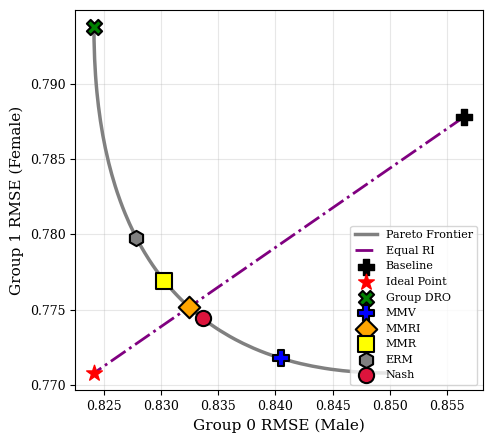

  Saved: ../figures_final/fig1_analog_CA_sex_MARC_employed.pdf


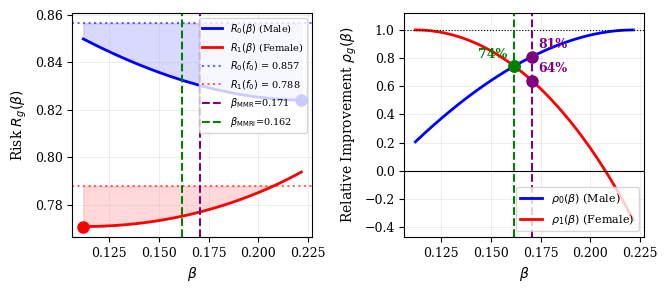

In [3]:
# (a) CA / sex / MARC
d_CA_sex_MARC = run_config('CA', 'sex', ['MARC'])
plot_pareto_front(d_CA_sex_MARC,
    f'{OUT_DIR}/intro_diff_scale_CA_sex_MARC_employed')
plot_beta_sweep(d_CA_sex_MARC,
    f'{OUT_DIR}/fig1_analog_CA_sex_MARC_employed')

Removed 182213 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 196604 -> 118073


Removed 76 samples with non-positive income
Selected 1 features: ['AGEP']
Loaded 117997 samples, 1 features, 2 groups (group_by=race_binary)


CA/race_binary/['AGEP']  ratio=2.1391
  MMR:  White=84.6%  Non-White=67.1%
  MMRI: White=78.0%  Non-White=78.0%


  Saved: ../figures_final/intro_diff_scale_CA_race_binary_AGEP_employed.pdf


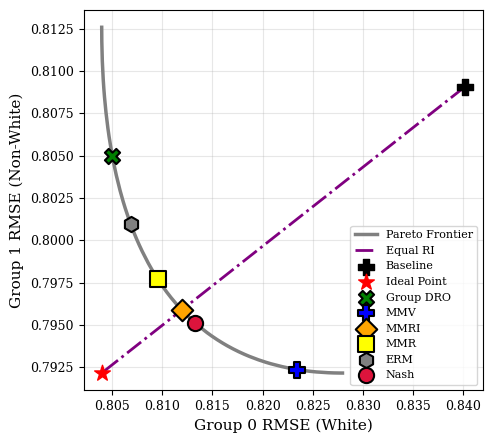

  Saved: ../figures_final/fig1_analog_CA_race_binary_AGEP_employed.pdf


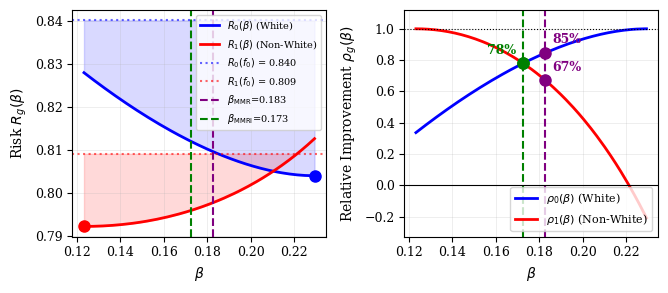

In [4]:
# (b) CA / race / AGEP
d_CA_race_AGEP = run_config('CA', 'race_binary', ['AGEP'])
plot_pareto_front(d_CA_race_AGEP,
    f'{OUT_DIR}/intro_diff_scale_CA_race_binary_AGEP_employed')
plot_beta_sweep(d_CA_race_AGEP,
    f'{OUT_DIR}/fig1_analog_CA_race_binary_AGEP_employed')

Removed 6631 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 7769 -> 4669
Removed 2 samples with non-positive income
Selected 1 features: ['MARC']
Loaded 4667 samples, 1 features, 2 groups (group_by=sex)


HI/sex/['MARC']  ratio=2.1653
  MMR:  Male=66.4%  Female=27.3%
  MMRI: Male=52.6%  Female=52.6%


  Saved: ../figures_final/intro_diff_scale_HI_sex_MARC_employed.pdf


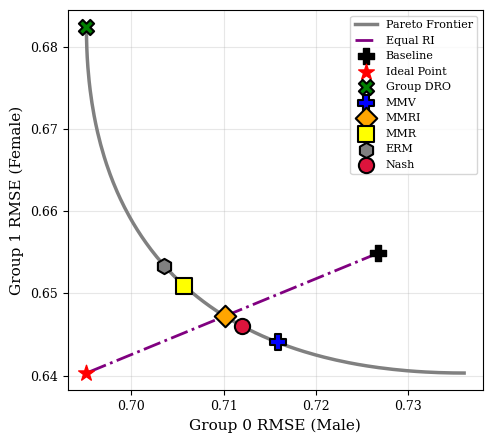

  Saved: ../figures_final/fig1_analog_HI_sex_MARC_employed.pdf


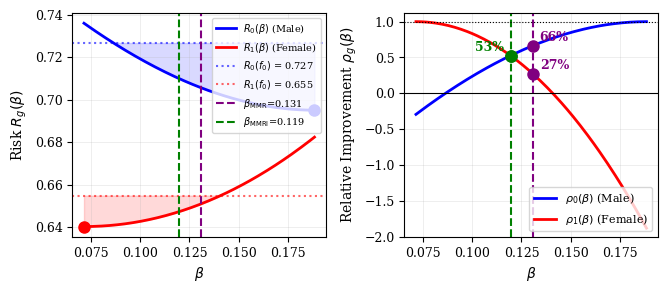

In [5]:
# (c) HI / sex / MARC
d_HI_sex_MARC = run_config('HI', 'sex', ['MARC'])
plot_pareto_front(d_HI_sex_MARC,
    f'{OUT_DIR}/intro_diff_scale_HI_sex_MARC_employed',
    legend_loc='upper right')
plot_beta_sweep(d_HI_sex_MARC,
    f'{OUT_DIR}/fig1_analog_HI_sex_MARC_employed')

Removed 6631 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 7769 -> 4669
Removed 2 samples with non-positive income
Selected 1 features: ['AGEP']
Loaded 4667 samples, 1 features, 2 groups (group_by=race_binary)


HI/race_binary/['AGEP']  ratio=3.4810
  MMR:  White=78.1%  Non-White=23.7%
  MMRI: White=63.3%  Non-White=63.3%


  Saved: ../figures_final/intro_diff_scale_HI_race_binary_AGEP_employed.pdf


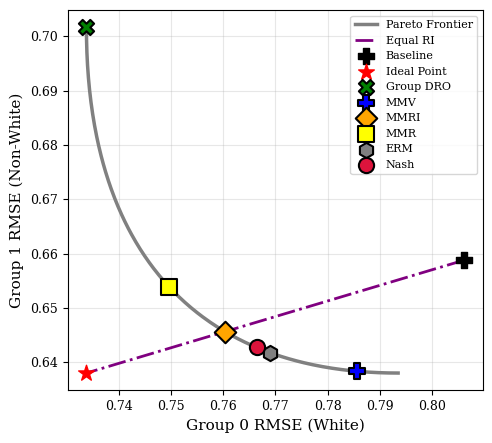

  Saved: ../figures_final/fig1_analog_HI_race_binary_AGEP_employed.pdf


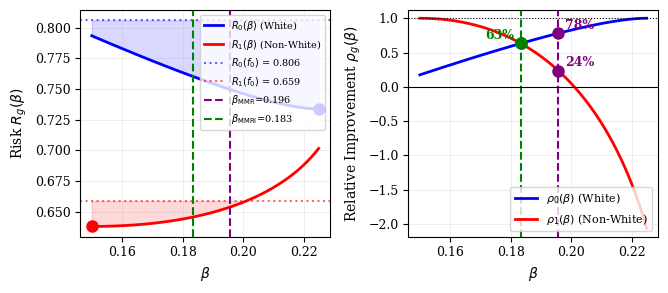

In [6]:
# (d) HI / race / AGEP
d_HI_race_AGEP = run_config('HI', 'race_binary', ['AGEP'])
plot_pareto_front(d_HI_race_AGEP,
    f'{OUT_DIR}/intro_diff_scale_HI_race_binary_AGEP_employed',
    legend_loc='upper right')
plot_beta_sweep(d_HI_race_AGEP,
    f'{OUT_DIR}/fig1_analog_HI_race_binary_AGEP_employed')

Removed 3370 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 4506 -> 2785
Removed 5 samples with non-positive income
Selected 1 features: ['SCHL']
Loaded 2780 samples, 1 features, 2 groups (group_by=sex)


ND/sex/['SCHL']  ratio=0.3256
  MMR:  Male=-28.1%  Female=58.3%
  MMRI: Male=31.3%  Female=31.3%


  Saved: ../figures_final/intro_diff_scale_ND_sex_SCHL_employed.pdf


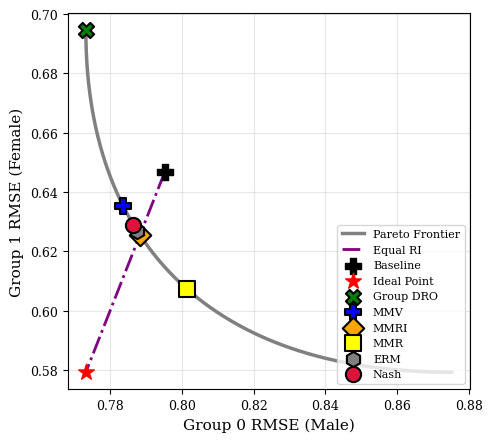

  Saved: ../figures_final/fig1_analog_ND_sex_SCHL_employed.pdf


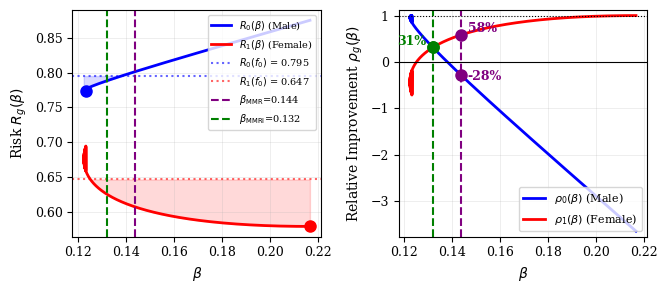

In [7]:
# (e) ND / sex / SCHL
d_ND_sex_SCHL = run_config('ND', 'sex', ['SCHL'])
plot_pareto_front(d_ND_sex_SCHL,
    f'{OUT_DIR}/intro_diff_scale_ND_sex_SCHL_employed')
plot_beta_sweep(d_ND_sex_SCHL,
    f'{OUT_DIR}/fig1_analog_ND_sex_SCHL_employed')

Removed 3370 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 4506 -> 2785
Removed 5 samples with non-positive income
Selected 1 features: ['AGEP']
Loaded 2780 samples, 1 features, 2 groups (group_by=race_binary)


ND/race_binary/['AGEP']  ratio=0.1010
  MMR:  White=-73.6%  Non-White=82.5%
  MMRI: White=56.9%  Non-White=56.9%


  Saved: ../figures_final/intro_diff_scale_ND_race_binary_AGEP_employed.pdf


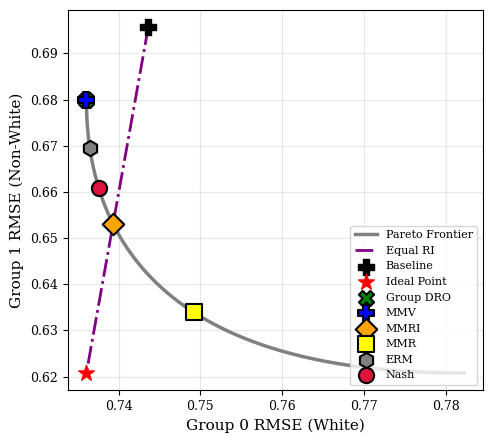

In [8]:
# (f) ND / race / AGEP  -- also Figure 5
# Panel (f) of Figure 9 (= Figure 1) is drawn by figure1_nd_race_age.ipynb.
d_ND_race_AGEP = run_config('ND', 'race_binary', ['AGEP'])
plot_pareto_front(d_ND_race_AGEP,
    f'{OUT_DIR}/intro_diff_scale_ND_race_binary_AGEP_employed')

## Four-feature models (Figure 10)

Removed 182213 samples with NaN values


Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 196604 -> 118073
Removed 76 samples with non-positive income
Selected 4 features: ['AGEP', 'SCHL', 'MARC', 'RELPC']
Loaded 117997 samples, 4 features, 2 groups (group_by=sex)


CA/sex/['AGEP', 'SCHL', 'MARC', 'RELPC']  ratio=1.2200
  MMR:  Male=93.0%  Female=91.5%
  MMRI: Male=92.3%  Female=92.3%


  Saved: ../figures_final/intro_diff_scale_CA_sex_all_features_employed.pdf


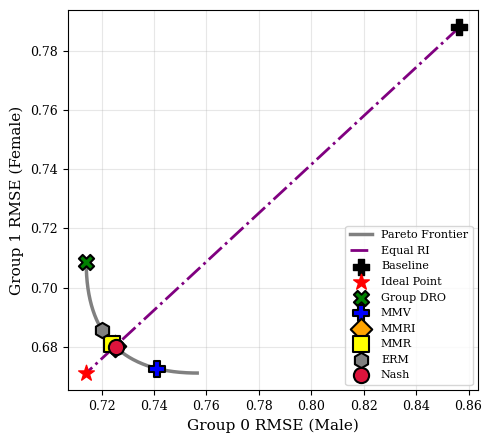

In [9]:
# CA / sex / all 4
d_CA_sex_all4 = run_config('CA', 'sex', FEATS_4)
plot_pareto_front(d_CA_sex_all4,
    f'{OUT_DIR}/intro_diff_scale_CA_sex_all_features_employed')

Removed 182213 samples with NaN values


Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 196604 -> 118073
Removed 76 samples with non-positive income
Selected 4 features: ['AGEP', 'SCHL', 'MARC', 'RELPC']
Loaded 117997 samples, 4 features, 2 groups (group_by=race_binary)


CA/race_binary/['AGEP', 'SCHL', 'MARC', 'RELPC']  ratio=1.1359
  MMR:  White=97.2%  Non-White=96.8%
  MMRI: White=97.0%  Non-White=97.0%


  Saved: ../figures_final/intro_diff_scale_CA_race_binary_all_features_employed.pdf


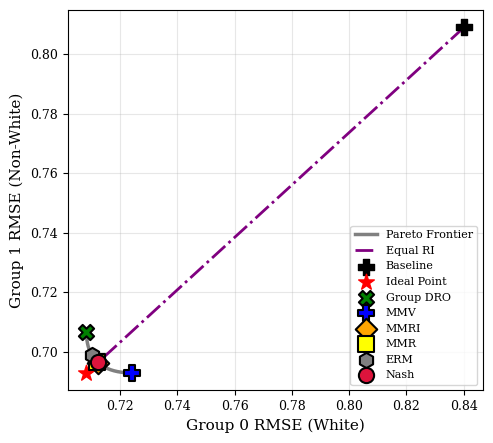

In [10]:
# CA / race / all 4
d_CA_race_all4 = run_config('CA', 'race_binary', FEATS_4)
plot_pareto_front(d_CA_race_all4,
    f'{OUT_DIR}/intro_diff_scale_CA_race_binary_all_features_employed')

Removed 6631 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 7769 -> 4669
Removed 2 samples with non-positive income
Selected 4 features: ['AGEP', 'SCHL', 'MARC', 'RELPC']
Loaded 4667 samples, 4 features, 2 groups (group_by=sex)


HI/sex/['AGEP', 'SCHL', 'MARC', 'RELPC']  ratio=1.3972
  MMR:  Male=86.8%  Female=81.6%
  MMRI: Male=84.6%  Female=84.6%


  Saved: ../figures_final/intro_diff_scale_HI_sex_all_features_employed.pdf


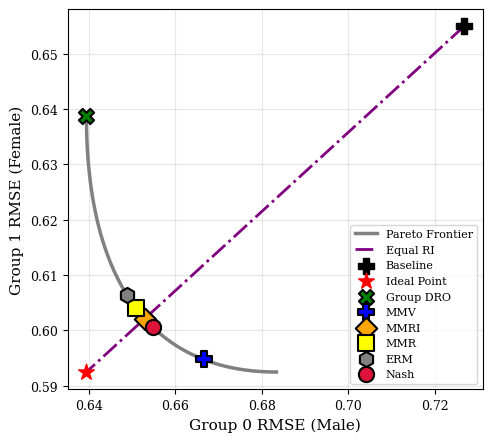

In [11]:
# HI / sex / all 4
d_HI_sex_all4 = run_config('HI', 'sex', FEATS_4)
plot_pareto_front(d_HI_sex_all4,
    f'{OUT_DIR}/intro_diff_scale_HI_sex_all_features_employed')

Removed 6631 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 7769 -> 4669
Removed 2 samples with non-positive income
Selected 4 features: ['AGEP', 'SCHL', 'MARC', 'RELPC']
Loaded 4667 samples, 4 features, 2 groups (group_by=race_binary)


HI/race_binary/['AGEP', 'SCHL', 'MARC', 'RELPC']  ratio=1.7126
  MMR:  White=91.5%  Non-White=85.5%
  MMRI: White=89.1%  Non-White=89.1%


  Saved: ../figures_final/intro_diff_scale_HI_race_binary_all_features_employed.pdf


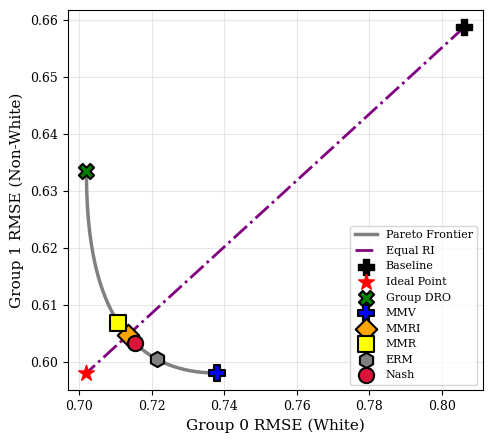

In [12]:
# HI / race / all 4
d_HI_race_all4 = run_config('HI', 'race_binary', FEATS_4)
plot_pareto_front(d_HI_race_all4,
    f'{OUT_DIR}/intro_diff_scale_HI_race_binary_all_features_employed')

Removed 3370 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 4506 -> 2785
Removed 5 samples with non-positive income
Selected 4 features: ['AGEP', 'SCHL', 'MARC', 'RELPC']
Loaded 2780 samples, 4 features, 2 groups (group_by=sex)


ND/sex/['AGEP', 'SCHL', 'MARC', 'RELPC']  ratio=0.5273
  MMR:  Male=32.1%  Female=64.2%
  MMRI: Male=51.4%  Female=51.5%


  Saved: ../figures_final/intro_diff_scale_ND_sex_employed_all4.pdf


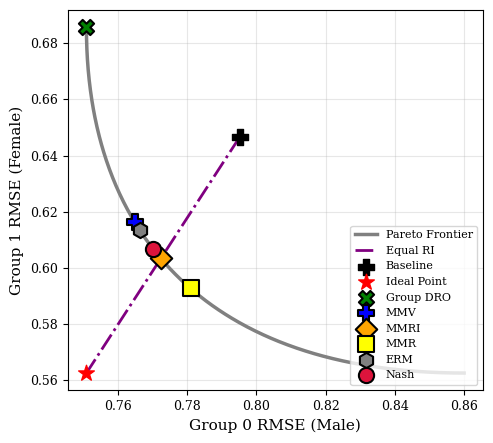

In [13]:
# ND / sex / all 4
d_ND_sex_all4 = run_config('ND', 'sex', FEATS_4)
plot_pareto_front(d_ND_sex_all4,
    f'{OUT_DIR}/intro_diff_scale_ND_sex_employed_all4')

Removed 3370 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 4506 -> 2785
Removed 5 samples with non-positive income
Selected 4 features: ['AGEP', 'SCHL', 'MARC', 'RELPC']
Loaded 2780 samples, 4 features, 2 groups (group_by=race_binary)


ND/race_binary/['AGEP', 'SCHL', 'MARC', 'RELPC']  ratio=0.3175
  MMR:  White=63.6%  Non-White=88.4%
  MMRI: White=81.4%  Non-White=81.4%


  Saved: ../figures_final/intro_diff_scale_ND_race_binary_employed_all4.pdf


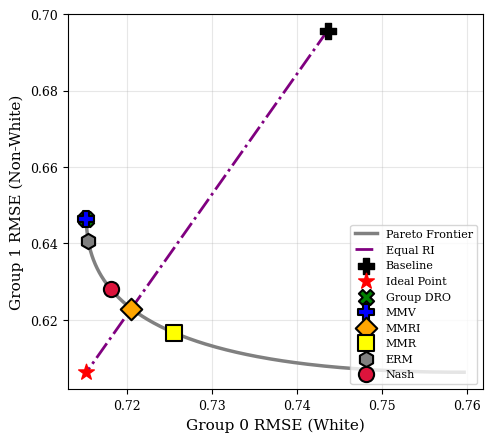

In [14]:
# ND / race / all 4
d_ND_race_all4 = run_config('ND', 'race_binary', FEATS_4)
plot_pareto_front(d_ND_race_all4,
    f'{OUT_DIR}/intro_diff_scale_ND_race_binary_employed_all4')